# Playground - Apartment Prices Prediction
by $\mathbb{JX}$

## Setup

In [62]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

In [63]:
# plotting helpers for EDA
def plot_hist(df, col, log=False, bins=50):
    """Histogram of one numeric column; log=True plots log(1 + col)."""
    sl_plot = df[col].dropna()
    if log:
        sl_plot = np.log1p(sl_plot)
    label = f'log(1 + {col})' if log else col

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(sl_plot, bins=bins)
    ax.set_title(label)
    ax.set_xlabel(label)
    ax.set_ylabel('count')
    plt.show()

def plot_counts(df, l_cols, levels=None):
    """Bar chart of counts per level, one panel per column (shared y-axis), for discrete columns.
    levels: e.g. range(1, 11) to keep levels with zero houses on the x-axis."""
    fig, axes = plt.subplots(1, len(l_cols), figsize=(6 * len(l_cols), 4), sharey=True, squeeze=False)
    for ax, col in zip(axes.flat, l_cols):
        sl_counts = df[col].value_counts().sort_index()
        if levels is not None:
            sl_counts = sl_counts.reindex(levels, fill_value=0)
        ax.bar(sl_counts.index.astype(str), sl_counts.values)
        ax.set_title(col)
    axes[0, 0].set_ylabel('count')
    plt.tight_layout()
    plt.show()

def plot_boxes(df, l_cols, ncols=4):
    """One boxplot per column (own y-axis each, since scales differ)."""
    nrows = math.ceil(len(l_cols) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.5 * nrows), squeeze=False)
    for ax, col in zip(axes.flat, l_cols):
        ax.boxplot(df[col].dropna())
        ax.set_title(col)
        ax.set_xticks([])
    for ax in axes.flat[len(l_cols):]:  # hide unused panels
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()

def plot_scatter(df, x, y, alpha=0.4):
    """Scatter of y against x, with their correlation in the title."""
    r = df[x].corr(df[y])

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(df[x], df[y], alpha=alpha)
    ax.set_title(f'{y} vs {x}  (r = {r:.2f})')
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    plt.show()

In [64]:
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
df_data = pd.read_csv(ROOT / "data" / "train.csv")

## Understanding the dataset + cleaning

In [65]:
na_summary = pd.DataFrame({
    "count_na": df_data.isna().sum(),
    "count_total": len(df_data),
    "pct_na": round(df_data.isna().mean()*100, 2)
})

na_summary[na_summary['count_na']>0].sort_values('pct_na', ascending=False)

,count_na,count_total,pct_na
PoolQC,1453,1460,99.52
MiscFeature,1406,1460,96.30
Alley,1369,1460,93.77
Fence,1179,1460,80.75
MasVnrType,872,1460,59.73
FireplaceQu,690,1460,47.26
LotFrontage,259,1460,17.74
GarageType,81,1460,5.55
GarageYrBlt,81,1460,5.55
GarageFinish,81,1460,5.55


Notes on features with NA values: 
  * `PoolQC` : NAs represent no pool
  * `MiscFeature`: NAs represent no misc feature
  * `Alley`: NAs represent no alley access
  * `Fence`: NAs represent no fence
  * `MasVnrType`: None -> no masonry veneer
  * `FireplaceQu`: NA -> no fireplace
  * `LotFrontage`: 'Linear feet of street connected to property' - TBC
  * `GarageType`: NA -> no garage (generally, the NAs in garage are all the same number corresponding to the observations with no garage)
  * `GarageYrBlt`: NA -> probably no garage
  * `GarageFinish`: NA -> no garage
  * `GarageQual`: NA -> no garage
  * `GarageCond`: NA -> no garage 
  * `BsmtFinType2`: NA -> No basement
  * `BsmtExposure`: NA -> no basement
  * `BsmtFinType1`: NA -> no basement
  * `BsmtCond`: NA -> no basement
  * `BsmtQual`: NA -> no basement
  * `MasVnrArea`: NA -> **actually check**
  * `Electrical`: NA --> **actually check**

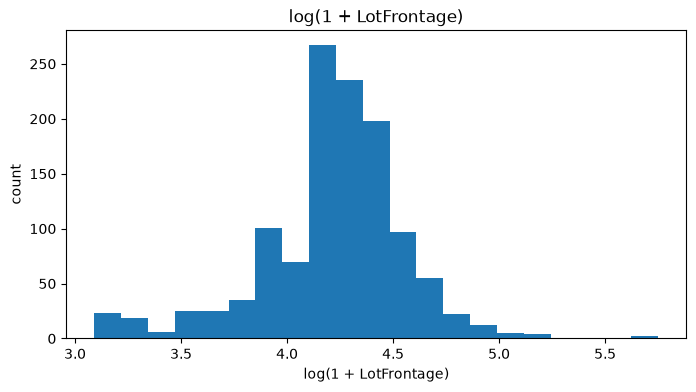

In [78]:
# distribution of a numeric column
plot_hist(df_data, col='LotFrontage', log=True, bins=21)

In [67]:
df_data[df_data['LotFrontage'].isna()]['GarageType'].value_counts()

GarageType
Attchd     176
Detchd      47
BuiltIn     23
Basment      4
CarPort      1
2Types       1
Name: count, dtype: int64

In [68]:
df_data[(df_data['MasVnrArea'].isna()) | (df_data['MasVnrArea']==0)]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
5,6,50,RL,85.0,14115,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,Shed,700,10,2009,WD,Normal,143000
8,9,50,RM,51.0,6120,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2008,WD,Abnorml,129900
9,10,190,RL,50.0,7420,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2008,WD,Normal,118000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1454,1455,20,FV,62.0,7500,Pave,Pave,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,10,2009,WD,Normal,185000
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125


## EDA

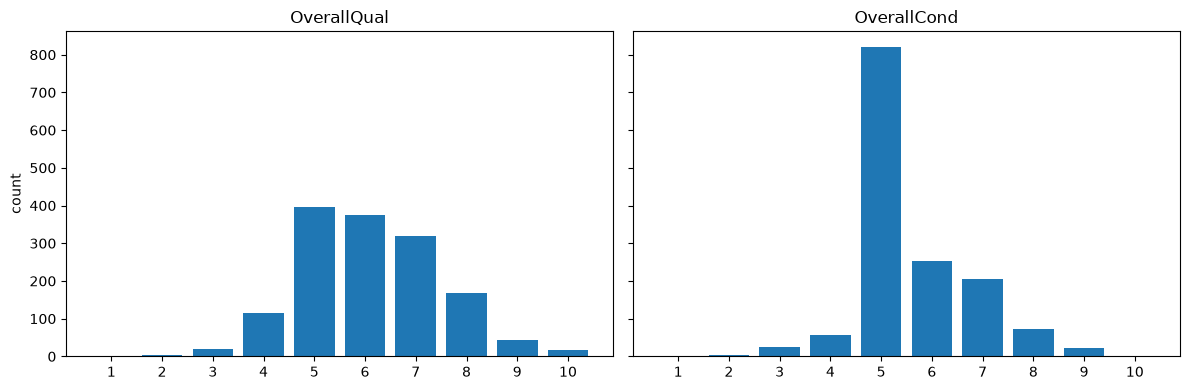

In [73]:
# distributions of OverallQual and OverallCond (1-10 ratings)
l_plot_vars = ['OverallQual', 'OverallCond']
plot_counts(df_data, l_plot_vars, levels=range(1, 11))

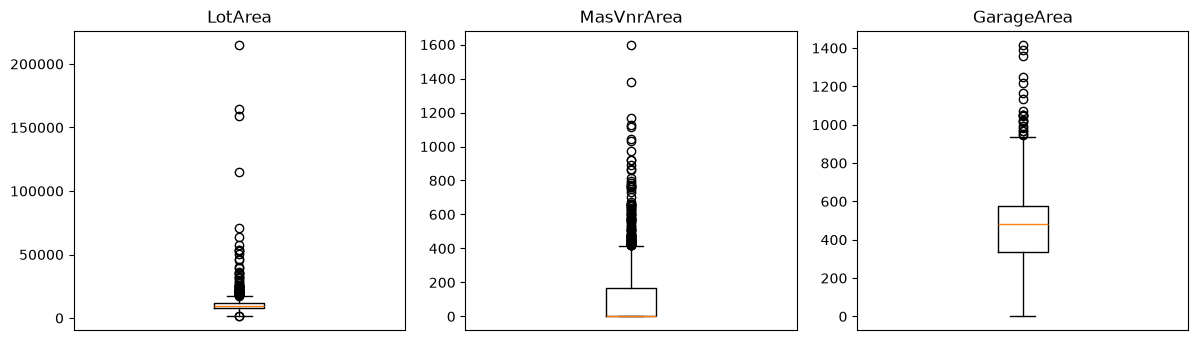

In [77]:
plot_boxes(df_data, ['LotArea', 'MasVnrArea', 'GarageArea'])

## Naive model

Approach: let's try to predict price per square feet using the features, then use that to calculate our final predictions. 

Let's just compare a few features for a start. Just eyeballing, I'm gonna do an OLS with the following features, and with my intuition noted too: 
* `BldgType` - type of dwelling. This immediately stratifies the buyer base who may have very different economic conditions. 
* `YearBuilt` and `YearRemodAdd` - probably take the later of. Age of residence should have an impact on price (newer = better probably) but may require scaling; don't expect this to be a linear relationship. 
* `TotalBsmtSF` - maybe just start with a binary yes/no - I suspect houses with basements are different from houses without basements. 
* `CentralAir` - central air conditioning. Just because it's binary and it's easy ^_^
* `1stFlrSF`, `2ndFlrSF` - maybe enginner a total square footage? 
* `Bedroom`, `Kitchen`
* `GarageArea`
* `PoolArea`